In [78]:
import pandas as pd

X = pd.read_csv("/home/thinkpad/Documents/BrototypeStudying/paper_three/Paper3/data/unsupervised_customers.csv")

In [79]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   annual_income_k  100 non-null    float64
 1   spending_score   100 non-null    float64
 2   age              100 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 2.5 KB


In [80]:
X.head(5)

,annual_income_k,spending_score,age
0,31.9,96.4,23
1,20.3,74.0,25
2,11.4,79.1,25
3,20.6,78.8,25
4,12.9,83.1,19


In [81]:
X.columns

Index(['annual_income_k', 'spending_score', 'age'], dtype='str')

In [82]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

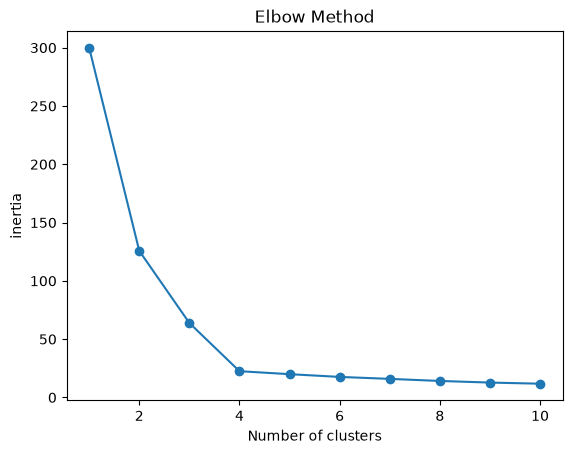

In [83]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker = "o")
plt.xlabel("Number of clusters")
plt.ylabel("inertia")
plt.title("Elbow Method")
plt.show()

In [84]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

data = pd.read_csv("/home/thinkpad/Documents/BrototypeStudying/paper_three/Paper3/data/unsupervised_customers.csv")

scaler = StandardScaler()
X = scaler.fit_transform(data)

model = KMeans(n_clusters=4, n_init=10, random_state=42)
model.fit(X)

data["cluster"] = model.labels_

print(silhouette_score(X, model.labels_))

0.6892371621231806


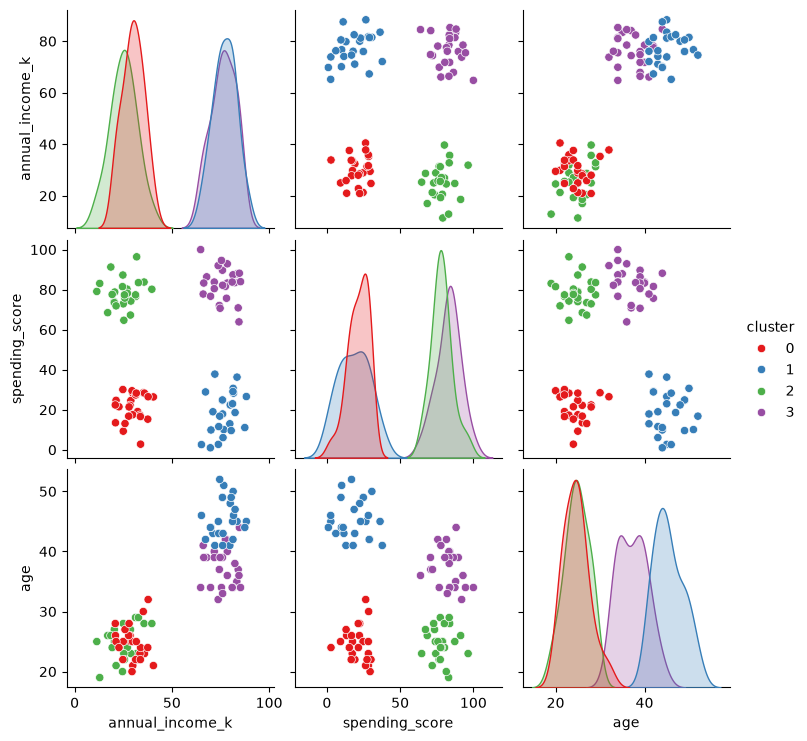

In [85]:
import seaborn as sns

sns.pairplot(data, hue="cluster", palette="Set1")

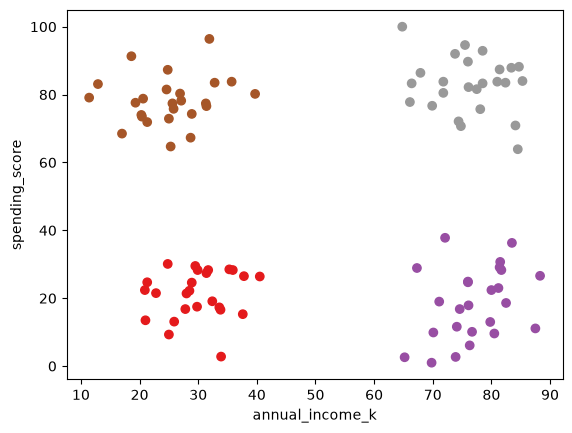

In [86]:
plt.scatter(data["annual_income_k"], data["spending_score"], c=data["cluster"], cmap="Set1")
plt.xlabel("annual_income_k")
plt.ylabel("spending_score")
plt.show()

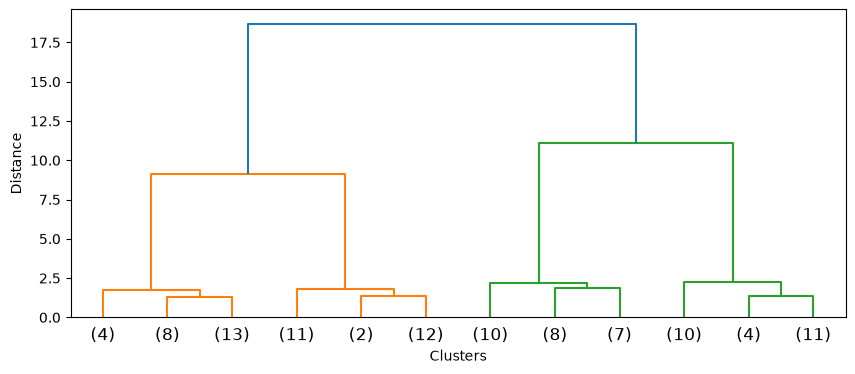

In [87]:
from scipy.cluster.hierarchy import dendrogram, linkage

Z = linkage(X, method="ward")
plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=12)
plt.xlabel("Clusters")
plt.ylabel("Distance")
plt.show()

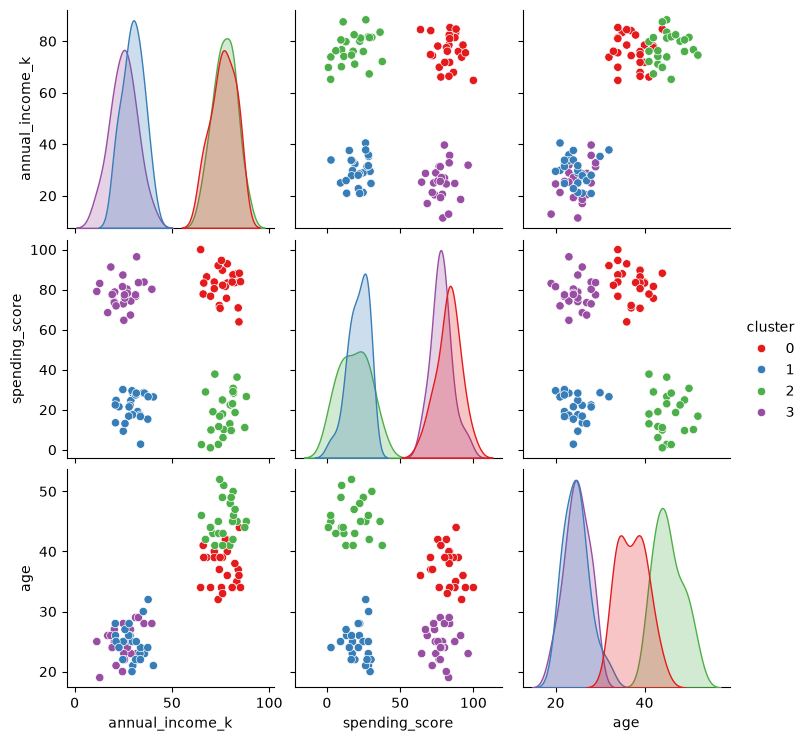

In [88]:
from sklearn.cluster import AgglomerativeClustering

model = AgglomerativeClustering(n_clusters=4, linkage='ward')
model.fit(X)

data["cluster"] = model.labels_

sns.pairplot(data, hue="cluster", palette="Set1")